In [24]:
import sys
import numpy as np

print(sys.executable)
print(np.__version__)

/home/ec2-user/scientific-ai-portfolio/.venv/bin/python
2.5.4


In [25]:
from pathlib import Path
import tifffile
import matplotlib.pyplot as plt

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

image_dir = project_root / "data/raw/bbbc039/images/images"
image_paths = sorted(image_dir.glob("*.tif"))

print("Number of images:", len(image_paths))

Number of images: 200


In [26]:
image = tifffile.imread(image_paths[0])

print("Shape:", image.shape)
print("Data type:", image.dtype)
print("First Pixel:", image[0,0])

Shape: (520, 696)
Data type: uint16
First Pixel: 145


In [27]:
# Task 1: Get the pixel value at row 100, column 200
print(image[99, 199])

# Task 2: Get the total number of pixels
print(image.size)

# Task 3: Get the center pixel value
center_row = image.shape[0] // 2
center_col = image.shape[1] // 2

print(image[center_row, center_col])

164
361920
161


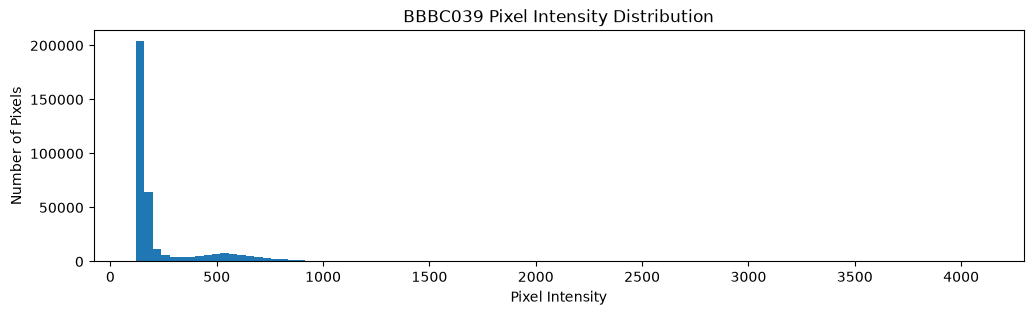

In [28]:
plt.figure(figsize=(12,3))

plt.hist(image.ravel(), bins= (100))

plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.title("BBBC039 Pixel Intensity Distribution")

plt.show()

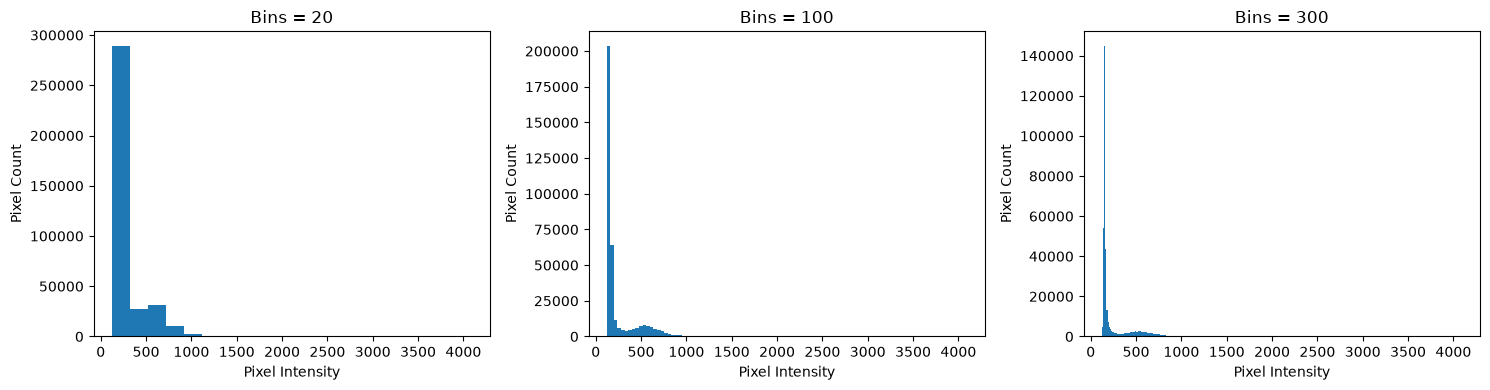

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, bins in zip(axes, [20, 100, 300]):
    ax.hist(image.ravel(), bins=bins)
    ax.set_title(f"Bins = {bins}")
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

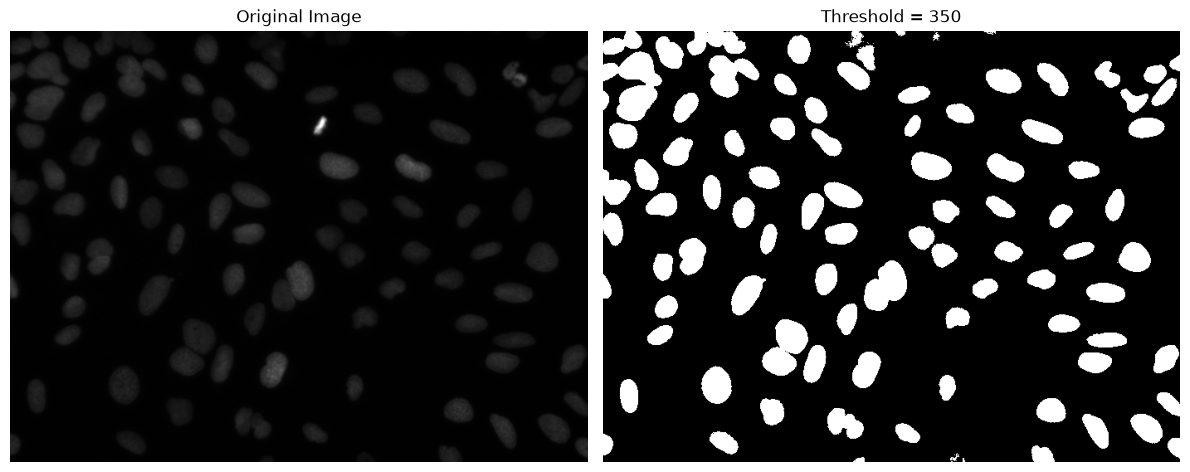

In [30]:
threshold = 350
mask = image > threshold

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title(f"Threshold = {threshold}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
from skimage.filters import threshold_otsu

otsu_threshold = threshold_otsu(image)

print("Manual Threshold:", 350)
print("Otsu Threshold:", otsu_threshold)

Manual Threshold: 350
Otsu Threshold: 395


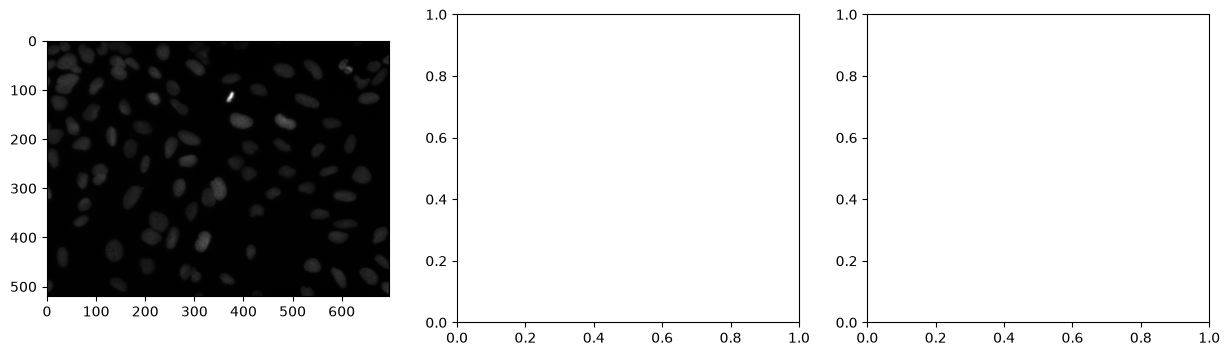

In [32]:
manual_mask = image > 350
ostu_mask = image > otsu_threshold

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(image, cmap="gray")

ROI shape: (100, 100)


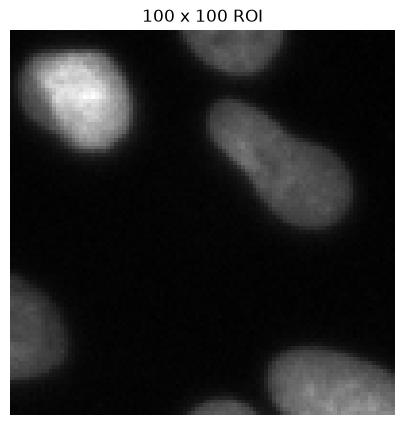

In [33]:
roi = image[100:200, 200:300]

print("ROI shape:", roi.shape)
plt.figure(figsize=(5, 5))
plt.imshow(roi, cmap="gray")
plt.title("100 x 100 ROI")
plt.axis("off")
plt.show()


In [34]:
print("Mean:", roi.mean())
print("Median:", np.median(roi))
print("Min:", roi.min())

Mean: 277.3977
Median: 165.0
Min: 136


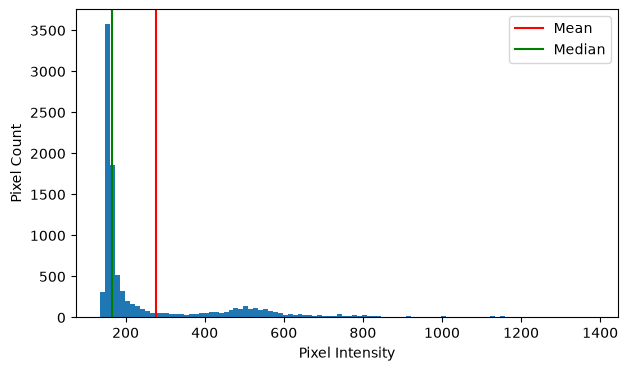

In [35]:
plt.figure(figsize=(7, 4))
plt.hist(roi.ravel(), bins=100)

plt.axvline(roi.mean(), color="red", label="Mean")
plt.axvline(np.median(roi), color="green", label="Median")

plt.xlabel("Pixel Intensity")
plt.ylabel("Pixel Count")
plt.legend()
plt.show()

In [36]:
mask_dir = project_root / "data/raw/bbbc039/masks"

mask_paths = sorted(mask_dir.rglob("*.png"))

print("Number of masks:", len(mask_paths))
print("First five masks:")

for path in mask_paths[:5]:
    print(path)

Number of masks: 200
First five masks:
/home/ec2-user/scientific-ai-portfolio/data/raw/bbbc039/masks/masks/IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB.png
/home/ec2-user/scientific-ai-portfolio/data/raw/bbbc039/masks/masks/IXMtest_A06_s6_w1B9577918-4973-4A87-BA73-A168AA755527.png
/home/ec2-user/scientific-ai-portfolio/data/raw/bbbc039/masks/masks/IXMtest_A09_s1_w1CE70AD49-290D-4312-82E6-CDC717F32637.png
/home/ec2-user/scientific-ai-portfolio/data/raw/bbbc039/masks/masks/IXMtest_A12_s7_w1EAEEA614-51ED-43B3-A4FF-088730911E4C.png
/home/ec2-user/scientific-ai-portfolio/data/raw/bbbc039/masks/masks/IXMtest_A15_s5_w1825174D4-ED30-490C-9635-6196417D6C9D.png


In [37]:
matching_masks = [
    path for path in mask_paths
    if path.stem == image_paths[0].stem
]

print("Matching masks:", len(matching_masks))

Matching masks: 1


In [38]:
from skimage.io import imread

gt = imread(matching_masks[0])

print("GT shape:", gt.shape)
print("GT dtype:", gt.dtype)
print("GT min:", gt.min())
print("GT max:", gt.max())

print("Unique labels:", np.unique(gt)[:20])

GT shape: (520, 696, 4)
GT dtype: uint8
GT min: 0
GT max: 255
Unique labels: [  0   1   2   3 255]


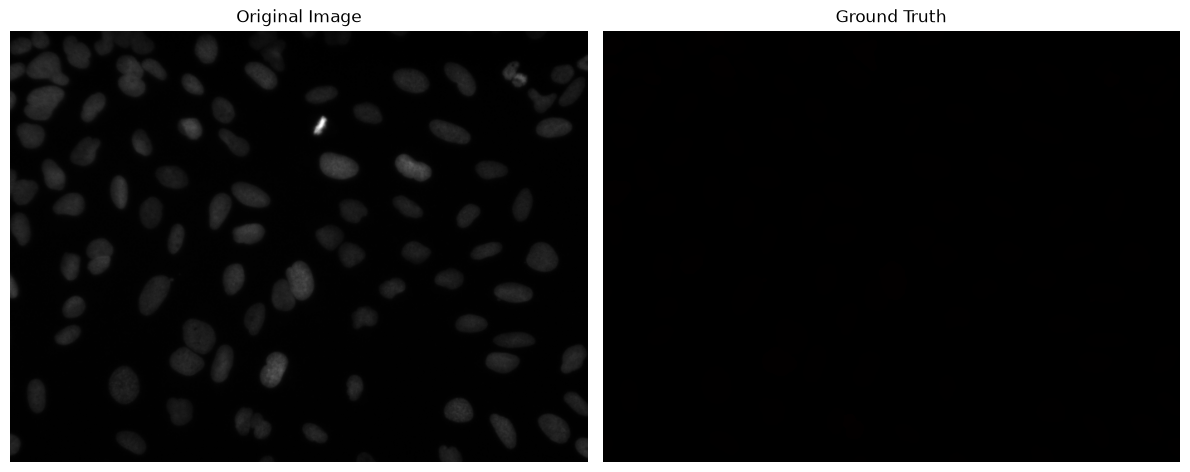

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(gt, cmap="nipy_spectral", interpolation="nearest")
axes[1].set_title("Ground Truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
print("Red:", np.unique(gt[:,:,0]))
print("Green:", np.unique(gt[:,:,1]))
print("Blue:", np.unique(gt[:,:,2]))
print("Alpha:", np.unique(gt[:,:,3]))

print("Top-left pixel:", gt[0, 0])
print("Center pixel:", gt[260, 348])

Red: [0 1 2 3]
Green: [0]
Blue: [0]
Alpha: [255]
Top-left pixel: [  0   0   0 255]
Center pixel: [  0   0   0 255]


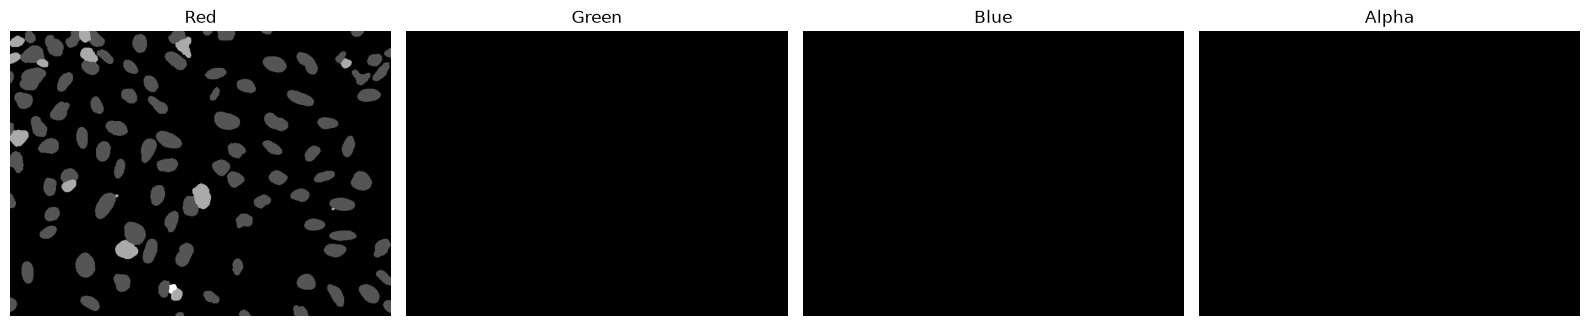

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

channels = ["Red", "Green", "Blue", "Alpha"]

for i, ax in enumerate(axes):
    ax.imshow(gt[:, :, i], cmap="gray")
    ax.set_title(channels[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
gt_binary = gt[:,:,0] > 0
print("GT shape:", gt_binary.shape)
print("GT dtype:", gt_binary.dtype)
print("Foreground pixels:", gt_binary.sum())

GT shape: (520, 696)
GT dtype: bool
Foreground pixels: 70682


In [43]:
manual_mask = image > 350
otsu_mask = image > otsu_threshold

print("Manual pixels:", manual_mask.sum())
print("Otsu pixels:", otsu_mask.sum())

Manual pixels: 69325
Otsu pixels: 64349


In [44]:
import numpy as np

def calculate_iou(prediction, ground_truth):
    intersection = np.logical_and(prediction, ground_truth).sum()
    union = np.logical_or(prediction, ground_truth).sum()

    if union == 0:
        return 1.0

    return intersection / union

manual_iou = calculate_iou(manual_mask, gt_binary)
otsu_iou = calculate_iou(otsu_mask, gt_binary)

print(f"Manual IoU: {manual_iou:.4f}")
print(f"Otsu IoU: {otsu_iou:.4f}")

Manual IoU: 0.9329
Otsu IoU: 0.8919


In [45]:
tp = np.logical_and(manual_mask, gt_binary).sum()
fp = np.logical_and(manual_mask, ~gt_binary).sum()
fn = np.logical_and(~manual_mask, gt_binary).sum()

print("True Positive:", tp)
print("False Positive:", fp)
print("False Negative:", fn)

iou = tp / (tp + fp + fn)

print(f"IOU: {iou:.4f}")

True Positive: 67572
False Positive: 1753
False Negative: 3110
IOU: 0.9329


In [46]:
from skimage.measure import label
manual_mask = image > 350
labeled_mask = label(manual_mask, connectivity = 2)
print("Original shape:", manual_mask.shape)
print("Labeled shape:", labeled_mask.shape)
print("Number of regions:", labeled_mask.max())

Original shape: (520, 696)
Labeled shape: (520, 696)
Number of regions: 102


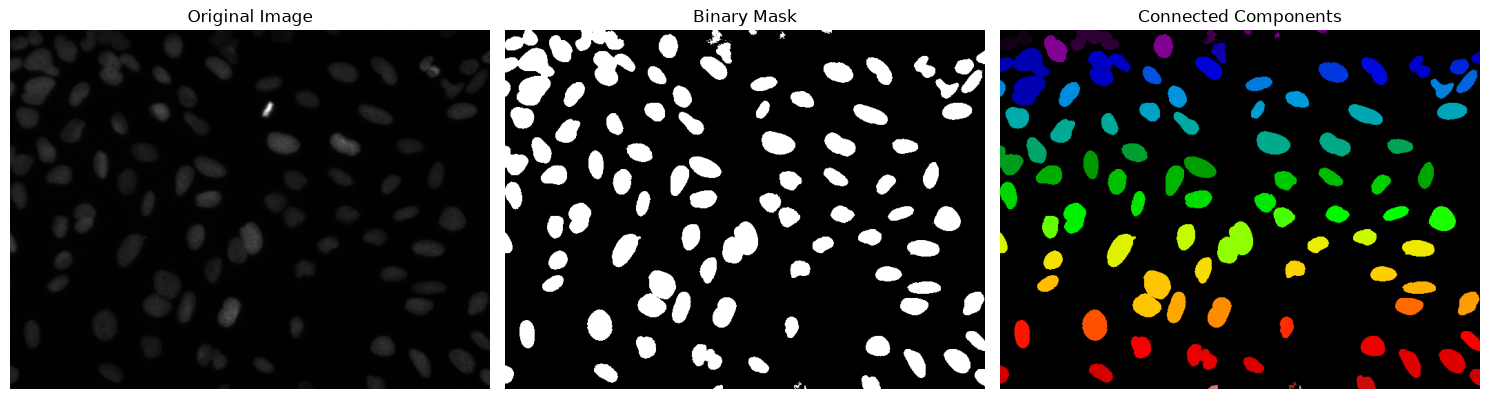

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title("Binary Mask")

axes[2].imshow(labeled_mask, cmap="nipy_spectral")
axes[2].set_title("Connected Components")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [49]:
from skimage.measure import regionprops
regions = regionprops(labeled_mask)
print("Number of regions: ", len(regions))
for region in regions[:5]:
    print("Label:", region.label, "Area:", region.area)

Number of regions:  102
Label: 1 Area: 830.0
Label: 2 Area: 1416.0
Label: 3 Area: 214.0
Label: 4 Area: 60.0
Label: 5 Area: 45.0


In [50]:
areas = [region.area for region in regions]
print("Minimum area:", min(areas))
print("Maximum area:", max(areas))
print("Mean area:", np.mean(areas))
print("Median area:", np.median(areas))

Minimum area: 1.0
Maximum area: 3260.0
Mean area: 679.656862745098
Median area: 661.0


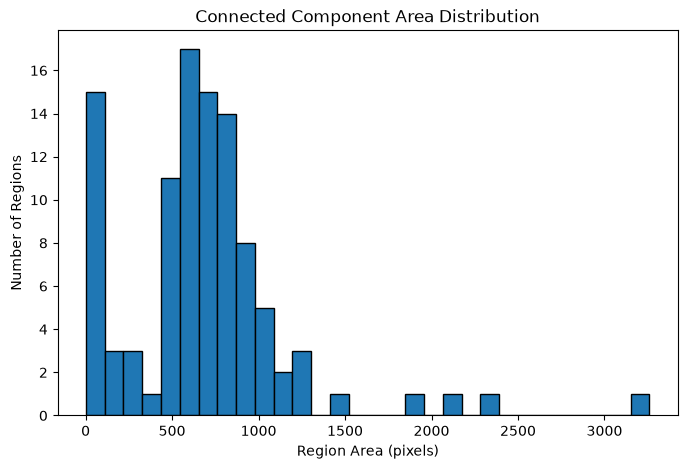

In [51]:
plt.figure(figsize=(8, 5))

plt.hist(areas, bins=30, edgecolor="black")

plt.xlabel("Region Area (pixels)")
plt.ylabel("Number of Regions")
plt.title("Connected Component Area Distribution")

plt.show()

In [29]:
from skimage.morphology import remove_small_objects
from skimage.measure import label

cleaned_mask = remove_small_objects(
    manual_mask,
    max_size=99,
    connectivity=2
)

cleaned_labels = label(cleaned_mask, connectivity=2)

print("Before:", labeled_mask.max())
print("After:", cleaned_labels.max())

Before: 102
After: 87


In [31]:
original_intersection = np.sum(manual_mask & gt_binary)
original_union = np.sum(manual_mask | gt_binary)

cleaned_intersection = np.sum(cleaned_mask & gt_binary)
cleaned_union = np.sum(cleaned_mask | gt_binary)

original_iou = original_intersection / original_union
cleaned_iou = cleaned_intersection / cleaned_union

print(f"Original IoU: {original_iou:.4f}")
print(f"Cleaned IoU: {cleaned_iou:.4f}")
print(f"IoU change: {cleaned_iou - original_iou:+.4f}")

Original IoU: 0.9329
Cleaned IoU: 0.9291
IoU change: -0.0038


In [32]:
removed_mask = manual_mask & ~cleaned_mask


removed_tp = np.sum(removed_mask & gt_binary)
removed_fp = np.sum(removed_mask & ~gt_binary)

total_removed = np.sum(removed_mask)

print("Total removed pixels:", total_removed)
print("Removed True Positives:", removed_tp)
print("Removed False Positives:", removed_fp)

print(f"TP percentage: {removed_tp / total_removed:.2%}")
print(f"FP percentage: {removed_fp / total_removed:.2%}")

Total removed pixels: 276
Removed True Positives: 275
Removed False Positives: 1
TP percentage: 99.64%
FP percentage: 0.36%
